In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if ROOT.name != 'jahwa': ROOT = ROOT / 'jahwa'
sys.path.insert(0, str(ROOT))
import torch
from pcb4_transfer import prepare, train, evaluate
DEVICE = '0' if torch.cuda.is_available() else 'cpu'
print('실행 환경:', sys.executable, DEVICE)

실행 환경: C:\Project\AI_Source\.venv\Scripts\python.exe 0


# 기존 PCB YOLO에 PCB4 추가 학습
목표: models/best.pt에서 시작해 기존 PCB + PCB4 실제 위치 라벨로 가중치를 미세조정합니다.

수업 연결: CNN03의 지역 특징/풀링, Pytorch08의 데이터 분할·역전파·최적화·평가·모델 저장 흐름을 객체 검출에 적용합니다. YOLO가 학습 루프를 수행합니다.

기존 9개 클래스 ID를 유지하고 PCB4의 5개 결함 클래스를 추가합니다. 정상 이미지는 빈 라벨입니다. PCB4는 유형별 60/20/20, 원본 데이터는 기존 분할을 유지합니다. test는 최종 후보를 정한 뒤 한 번 평가합니다.

이전에 저장된 ResNet 이상 탐지 수치는 이번 YOLO 성능이 아닙니다. 촬영 개체/세션 정보가 없어 유사 사진 누출 가능성은 남습니다. 자세한 내용은 SMALL_PCB.md를 참조하세요.

## 테스트를 보기 전에 고정한 평가 규칙
기존 PCB val mAP50-95 하락이 절대값 0.05 이내이고 PCB4 val 이미지 F1이 Baseline보다 높은 후보를 채택합니다. 이미지 점수는 모든 결함 후보의 최대 confidence(후보 하한 0.001), IoU=0.45, max_det=300입니다. 임계값은 val F1 최대, 동점이면 FP가 적은 값으로 정합니다. 테스트는 선정 후에만 실행하며 confidence는 확률이 아닙니다.

In [2]:
summary = prepare()
print(summary)
# data/pcb4_yolo/manifest.json에서 출처, 분할, 박스 수를 확인합니다.
# 실제 LabelMe 사각형만 변환하며 누락된 이상 주석은 오류로 중단합니다.

{'images': 200, 'classes': ['insufficient_solder', 'excess_solder', 'solder_bridge', 'solder_void', 'missing_component', 'shifted_component', 'burn', 'physical_damage', 'oxidation', 'pcb4_component_damage', 'pcb4_foreign_material', 'pcb4_miss', 'pcb4_oxidation', 'pcb4_scratch'], 'splits': {'train': 120, 'val': 40, 'test': 40}}


{'pcb4_images': 200, 'pcb4_normal': 100, 'pcb4_defective': 100, 'category_images': {'component_damage': 25, 'foreign_material': 20, 'good': 100, 'miss': 30, 'oxidation': 20, 'scratch': 5}, 'box_count_distribution': {1: 73, 2: 15, 0: 100, 3: 9, 4: 3}, 'boxes': 142, 'resolutions': {'1358x1104': 200}, 'area_px_quantiles': [3298.104469965589, 8759.716805998427, 15169.010173649247, 24942.35263154733, 63904.271431833695], 'boxes_under_32_squared_at_800': 0, 'pcb4_duplicates': [], 'original': {'train': {'images': 3836, 'normal': 344, 'defective': 3492, 'missing_labels': [], 'class_boxes': {1: 1550, 0: 2370, 3: 794, 6: 450, 4: 948, 2: 4160, 7: 1152, 5: 450, 8: 830}}, 'val': {'images': 687, 'normal': 433, 'defective': 254, 'missing_labels': [], 'class_boxes': {1: 111, 0: 187, 3: 104, 6: 31, 4: 74, 2: 181, 7: 15, 5: 31}}, 'test': {'images': 686, 'normal': 427, 'defective': 259, 'missing_labels': [], 'class_boxes': {1: 115, 3: 28, 0: 186, 6: 32, 4: 74, 2: 181, 7: 16, 5: 31}}}, 'original_exact_dup

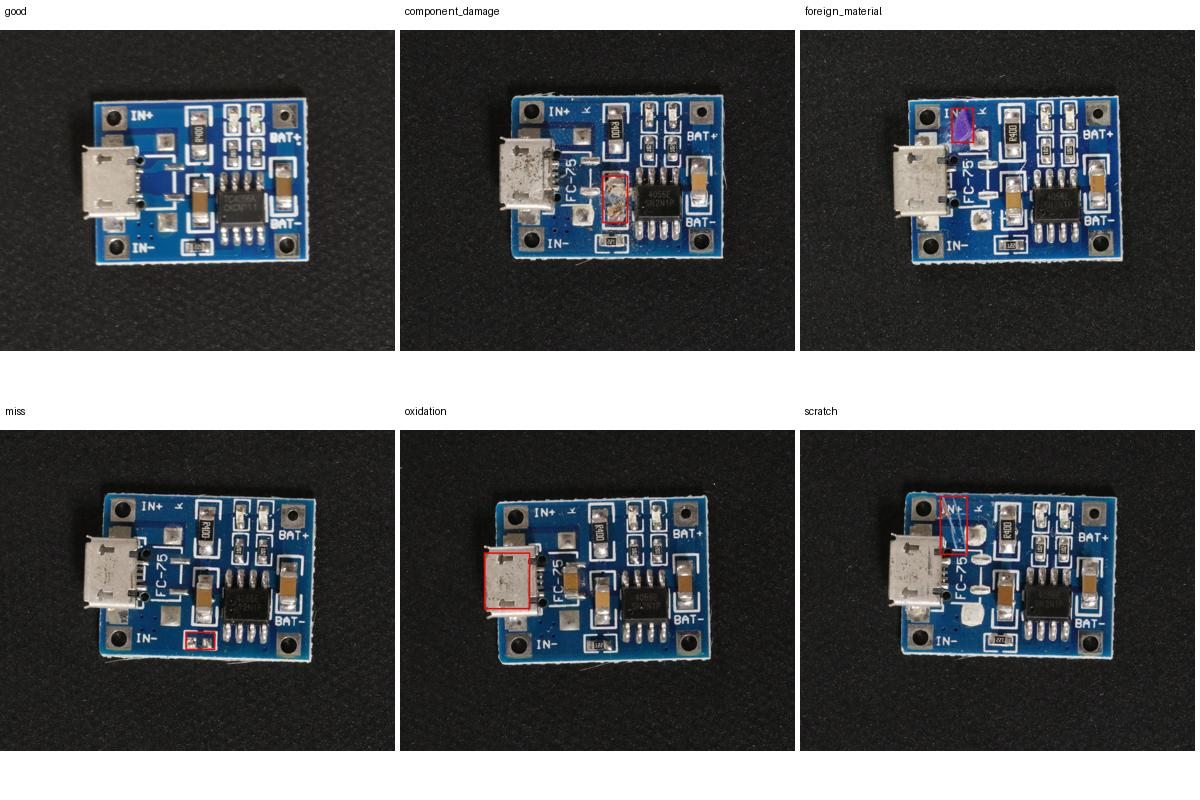

In [2]:
import importlib, pcb4_transfer
importlib.reload(pcb4_transfer)
audit = pcb4_transfer.audit_and_eda()
print(audit)
from IPython.display import display, Image
display(Image(filename=str(ROOT/'outputs/eda/representatives_boxes.jpg')))

In [5]:
import importlib, pcb4_transfer
importlib.reload(pcb4_transfer)
smoke_result = pcb4_transfer.train(epochs=1, device=DEVICE, smoke=True)
print('SMOKE:', smoke_result.save_dir)

Ultralytics 8.4.215  Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8124MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Project\AI_Source\jahwa\data\pcb4_yolo\smoke.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\Project\AI_Source\jahwa\models\best.pt, momentum=0.937, mosaic=1.0, mult

In [4]:
import importlib, pcb4_transfer
importlib.reload(pcb4_transfer)
baseline_original = pcb4_transfer.detection_eval(ROOT/'models/best.pt', 'original', 'val', DEVICE)
print(baseline_original)

Ultralytics 8.4.215  Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8124MiB)
YOLO26m summary (fused): 130 layers, 20,356,391 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 511.6±209.9 MB/s, size: 55.9 KB)
val: Scanning C:\Project\AI_Source\jahwa\data\final_solder\labels\val... 687 images, 433 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 687/687 3.0Kit/s 0.2s0.1ss
val: New cache created: C:\Project\AI_Source\jahwa\data\final_solder\labels\val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 172/172 4.6it/s 37.8s0.2ss
                   all        687        734      0.911      0.915      0.911      0.635
   insufficient_solder         43        187      0.929      0.983      0.969      0.601
         excess_solder         56        111       0.96      0.937      0.945       0.63
         solder_bridge         56        181       0.96      0.935      0.943   

In [6]:
import importlib, pcb4_transfer
importlib.reload(pcb4_transfer)
training_result = pcb4_transfer.train(epochs=30, device=DEVICE)
CANDIDATE = Path(training_result.save_dir) / 'weights/best.pt'
print('Candidate:', CANDIDATE)

Ultralytics 8.4.215  Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8124MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Project\AI_Source\jahwa\data\pcb4_yolo\mixed.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\Project\AI_Source\jahwa\models\best.pt, momentum=0.937, mosaic=1.0, mul

In [8]:
import importlib, pcb4_transfer
importlib.reload(pcb4_transfer)
selected, threshold, validation_rows, selection = pcb4_transfer.select_model(CANDIDATE, baseline_original, DEVICE)
print(selection)
# 모델과 임계값을 검증 데이터로 고정한 다음 테스트합니다.
if selection['accepted_finetune']:
    final_detection = pcb4_transfer.detection_eval(selected, 'pcb4', 'test', DEVICE)
else:
    final_detection = {'metrics': {}, 'note': '9-class baseline has no PCB4 class AP'}
original_test = pcb4_transfer.detection_eval(selected, 'original', 'test', DEVICE)
baseline_original_test = original_test if Path(selected)==ROOT/'models/best.pt' else pcb4_transfer.detection_eval(ROOT/'models/best.pt', 'original', 'test', DEVICE)
final_metrics = pcb4_transfer.export_integration(selected, threshold, final_detection, validation_rows, ROOT/'models/best.pt', DEVICE)
print(final_metrics)

Ultralytics 8.4.215  Python-3.11.9 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8124MiB)
YOLO26m summary (fused): 130 layers, 20,360,246 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 801.1±366.1 MB/s, size: 65.0 KB)
val: Scanning C:\Project\AI_Source\jahwa\data\final_solder\labels\val.cache... 687 images, 433 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 687/687  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 172/172 6.2it/s 27.6s0.1ss
                   all        687        734      0.938      0.873      0.935       0.65
   insufficient_solder         43        187      0.962      0.935      0.976      0.597
         excess_solder         56        111      0.957      0.874      0.946       0.61
         solder_bridge         56        181      0.954      0.923      0.942      0.596
           solder_void          4        104      0.924      0.814      0.955      0

In [15]:
# 최종 모델을 이용한 팀 API 및 실제 HTTP 업로드 검증
import importlib, inspect_pcb
importlib.reload(inspect_pcb)
from inspect_pcb import predict_pcb
import app, json, base64, threading, urllib.request
importlib.reload(app)
from http.server import ThreadingHTTPServer
server=ThreadingHTTPServer(('127.0.0.1',0),app.Handler)
threading.Thread(target=server.serve_forever,daemon=True).start()
checks=[]
try:
    url='http://127.0.0.1:'+str(server.server_address[1])
    with urllib.request.urlopen(url) as response: assert b'FoldedVision' in response.read()
    for category in ['good','component_damage']:
        sample=next((ROOT/'data/pcb4_yolo/images/test').glob(category+'_*.jpg'))
        for mode in ['baseline','final']:
            request=urllib.request.Request(url+'/inspect',data=json.dumps({'image':base64.b64encode(sample.read_bytes()).decode(),'product_id':'HTTP-DEMO','mode':mode}).encode(),headers={'Content-Type':'application/json'})
            with urllib.request.urlopen(request) as response: payload=json.load(response)
            assert payload['result']['status'] in ('OK','NG','REVIEW')
            assert payload['result']['inference_ms']>0
            assert base64.b64decode(payload['image']).startswith(bytes([255,216]))
            checks.append({'mode':mode,'image':sample.name,'result':payload['result']})
    from urllib.error import HTTPError
    bad=urllib.request.Request(url+'/inspect',data=json.dumps({'image':'not-base64','mode':'final'}).encode(),headers={'Content-Type':'application/json'})
    try:
        urllib.request.urlopen(bad)
        raise AssertionError('Invalid upload must fail')
    except HTTPError as error:
        assert error.code==400 and json.load(error)['status']=='REVIEW'
finally:
    server.shutdown();server.server_close()
pcb4_transfer.write_json(ROOT/'outputs/integration/http_verification.json',checks)
print('Real HTTP uploads PASS:',len(checks))

127.0.0.1 - - [19/Nov/2026 19:54:46] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [19/Nov/2026 19:54:46] "POST /inspect HTTP/1.1" 200 -
127.0.0.1 - - [19/Nov/2026 19:54:47] "POST /inspect HTTP/1.1" 200 -
127.0.0.1 - - [19/Nov/2026 19:54:47] "POST /inspect HTTP/1.1" 200 -
127.0.0.1 - - [19/Nov/2026 19:54:48] "POST /inspect HTTP/1.1" 200 -
127.0.0.1 - - [19/Nov/2026 19:54:48] "POST /inspect HTTP/1.1" 400 -


Real HTTP uploads PASS: 4


In [16]:
# 경로 / PIL / OpenCV 입력으로 실제 모델 API 검증
import cv2, numpy as np
from PIL import Image as PILImage
sample=next((ROOT/'data/pcb4_yolo/images/test').glob('good_*.jpg'))
with PILImage.open(sample) as source: pil_source=source.convert('RGB')
api_checks=[predict_pcb(sample),predict_pcb(pil_source),predict_pcb(cv2.imread(str(sample)))]
for checked in api_checks:
    assert checked['part_type']=='PCB' and checked['status'] in ('OK','NG','REVIEW')
    assert checked['mask_path'] is None and checked['inference_ms']>0
    assert 0<=checked['defect_score']<=1
try:
    predict_pcb(np.zeros((32,32,3),dtype=np.float32))
    raise AssertionError('Normalized float array must fail')
except ValueError:
    pass
pcb4_transfer.write_json(ROOT/'outputs/integration/api_verification.json',api_checks)
print('Real model API inputs PASS')

Real model API inputs PASS


In [11]:
# 실제 평가 결과만으로 포트폴리오 그래프와 원본 도메인 이미지 판정을 기록
portfolio=pcb4_transfer.portfolio_summary(baseline_original, selection, CANDIDATE)
selected_original_val=pcb4_transfer.image_predictions(selected, 'val', DEVICE, domain='original')
selected_original_test=pcb4_transfer.image_predictions(selected, 'test', DEVICE, domain='original')
pcb4_transfer.write_json(ROOT/'outputs/integration/selected_original_image_metrics.json', {'threshold_from':'PCB4 validation','threshold':threshold,'val':pcb4_transfer.classification_metrics(selected_original_val,threshold),'test':pcb4_transfer.classification_metrics(selected_original_test,threshold)})
import json
baseline_threshold=json.loads((ROOT/'outputs/integration/baseline_image_comparison.json').read_text(encoding='utf-8'))['baseline_threshold']
baseline_original_test_rows=selected_original_test if Path(selected)==ROOT/'models/best.pt' else pcb4_transfer.image_predictions(ROOT/'models/best.pt', 'test', DEVICE, domain='original')
pcb4_transfer.write_json(ROOT/'outputs/integration/original_image_test_comparison.json', {'thresholds_from':'PCB4 validation','baseline':pcb4_transfer.classification_metrics(baseline_original_test_rows,baseline_threshold),'selected':pcb4_transfer.classification_metrics(selected_original_test,threshold)})
print(portfolio['metrics'])

{'TP': 20, 'FP': 3, 'TN': 17, 'FN': 0, 'accuracy': 0.925, 'precision': 0.8695652173913043, 'recall': 1.0, 'f1': 0.9302325581395349, 'roc_auc': 1.0, 'average_precision': 1.0, 'false_positive_rate': 0.15, 'defect_inflow_reduction': 100.0, 'dataset_name': 'PCB4 zhaolutuan/0422 pinned custom split', 'task_type': 'image_binary_classification_and_object_detection', 'train_count': 120, 'validation_count': 40, 'test_count': 40, 'threshold': 0.10295861214399338, 'count_scope': 'PCB4 benchmark split; mixed training run used 3836 original + 120 PCB4 images', 'mixed_training_unique_images': 3956, 'mixed_training_normal': 404, 'mixed_training_defective': 3552, 'mAP50': 0.8388716356107659, 'mAP50_95': 0.5890462377911906, 'object_detection': {'weights': 'C:\\Project\\AI_Source\\jahwa\\models\\pcb_yolo_final.pt', 'domain': 'pcb4', 'split': 'test', 'metrics': {'metrics/precision(B)': 0.7742541845658927, 'metrics/recall(B)': 0.7925564293996519, 'metrics/mAP50(B)': 0.8388716356107659, 'metrics/mAP50-95(B

## 결과 파일과 해석
팀 전달 파일은 outputs/integration/pcb_predictions.csv, pcb_metrics.json, pcb_model_config.json입니다. 테스트 정답을 사용한 수치는 이미지 단위 판정 지표와 객체 검출 지표를 분리합니다. NG를 후속 공정 전에 분리한다는 조건에서 TP/(TP+FN)×100을 계산하며 실제 생산 불량률 개선으로 주장하지 않습니다. 상세 규약은 TEAM_INTEGRATION.md, 사전 고정 규칙은 EXPERIMENT_PROTOCOL.md를 참조하세요.

In [12]:
report=pcb4_transfer.write_final_report(CANDIDATE, baseline_original)
print(report)

# FoldedVision AI PCB — 실제 실행 결과 보고서

## 실제 학습 및 데이터

정식 학습: 30에포크, 고유 학습 사진 3,956장(원본3,836 + PCB4 120). 정상404 / 불량3,552. epoch 반복은 고유 이미지 증가로 집계하지 않았다.
Smoke Test는 원본6 + PCB4 유형별6 = 12장, 1에포크로 파이프라인만 검증했다.
PCB4 전체는 정상100/불량100, train120/val40/test40이다. test는 정상20/불량20이다. 결함 박스는 전체142개다.

추가 학습 후보 클래스: 기존 insufficient_solder, excess_solder, solder_bridge, solder_void, missing_component, shifted_component, burn, physical_damage, oxidation 및 신규 pcb4_component_damage, pcb4_foreign_material, pcb4_miss, pcb4_oxidation, pcb4_scratch.
동등한 어노테이션 정책이 확인되지 않아 의미가 비슷한 이름을 자동 통합하지 않았다. 클래스 통합 ablation은 수행하지 않았다.

## 객체 검출 성능

| validation 평가 | Precision | Recall | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|
| 기존 모델 / 원본 PCB | 91.05% | 91.46% | 91.07% | 63.49% |
| 추가 학습 후보 / 원본 PCB | 93.75% | 87.30% | 93.52% | 64.96% |
| 추가 학습 후보 / PCB4 | 71.99% | 59.53% | 72.01% | 43.62% |

| 원본 PCB test 평가 | Precision | Recall | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|
| Baseline | 82.39% | 88.47% | 88.31% |

In [14]:
# 최종 평가에서 확인된 원본 도메인 한계를 설정과 보고서에 기록 (선정/임계값 변경 없음)
import importlib, pcb4_transfer, json
importlib.reload(pcb4_transfer)
p=ROOT/'outputs/integration'
metrics=json.loads((p/'pcb_metrics.json').read_text(encoding='utf-8'))
config=json.loads((p/'pcb_model_config.json').read_text(encoding='utf-8'))
comparison=metrics['original_domain_test_comparison']
before=comparison['baseline']['metrics'];after=comparison['selected']['metrics']
config['evaluation_scope']='PCB4 adaptation PoC; original-domain retention gate used validation, not test'
config['original_test_tradeoff']={'baseline_box_recall':before['metrics/recall(B)'],'selected_box_recall':after['metrics/recall(B)'],'baseline_map50_95':before['metrics/mAP50-95(B)'],'selected_map50_95':after['metrics/mAP50-95(B)']}
limitation='Original-domain held-out box recall decreased; do not claim full retention or universal replacement of baseline'
if after['metrics/recall(B)']<before['metrics/recall(B)'] and limitation not in config['limitations']: config['limitations'].append(limitation)
pcb4_transfer.write_json(p/'pcb_model_config.json',config)
print(pcb4_transfer.write_final_report(CANDIDATE,baseline_original))

# FoldedVision AI PCB — 실제 실행 결과 보고서

## 실제 학습 및 데이터

정식 학습: 30에포크, 고유 학습 사진 3,956장(원본3,836 + PCB4 120). 정상404 / 불량3,552. epoch 반복은 고유 이미지 증가로 집계하지 않았다.
Smoke Test는 원본6 + PCB4 유형별6 = 12장, 1에포크로 파이프라인만 검증했다.
PCB4 전체는 정상100/불량100, train120/val40/test40이다. test는 정상20/불량20이다. 결함 박스는 전체142개다.

추가 학습 후보 클래스: 기존 insufficient_solder, excess_solder, solder_bridge, solder_void, missing_component, shifted_component, burn, physical_damage, oxidation 및 신규 pcb4_component_damage, pcb4_foreign_material, pcb4_miss, pcb4_oxidation, pcb4_scratch.
동등한 어노테이션 정책이 확인되지 않아 의미가 비슷한 이름을 자동 통합하지 않았다. 클래스 통합 ablation은 수행하지 않았다.

## 객체 검출 성능

| validation 평가 | Precision | Recall | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|
| 기존 모델 / 원본 PCB | 91.05% | 91.46% | 91.07% | 63.49% |
| 추가 학습 후보 / 원본 PCB | 93.75% | 87.30% | 93.52% | 64.96% |
| 추가 학습 후보 / PCB4 | 71.99% | 59.53% | 72.01% | 43.62% |

| 원본 PCB test 평가 | Precision | Recall | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|
| Baseline | 82.39% | 88.47% | 88.31% |